![DBAcademy](./Includes/images/common/db-academy.png)

# Demo - Lakeflow Designer Overview and Source Layer

## Overview

In the previous demo, you explored the source data and reviewed the medallion workflow you will build. In this demo, you will get oriented to **Lakeflow Designer** and build the **source layer** of that workflow. You will:

- Learn what Lakeflow Designer is and what problem it solves.
- Tour the Lakeflow Designer UI.
- Add three existing bronze tables to the canvas using three different methods: the **Source** operator, drag-and-drop from **Catalog Explorer**, and **Genie Code**.
- Upload a local CSV file to a Unity Catalog volume and ingest it as a fourth bronze table.

This is the first hands-on demo of the workshop. Continue with **03 - Build the Silver Layer** to clean and transform these bronze tables.

## Learning Objectives

By the end of this demo, you will be able to:

- **Describe** the purpose, value propositions, and target audience of Lakeflow Designer.
- **Identify** the main areas of the Lakeflow Designer UI, including the canvas, operators panel, parameters, compute selector, and preview pane.
- **Add** bronze tables to the canvas using three different methods: the **Source** operator, drag-and-drop from **Catalog Explorer**, and **Genie Code**.
- **Upload** a local CSV file to a managed Unity Catalog volume and ingest it as a new bronze table.

## REQUIRED PREREQUISITES
### If running in your own Workspace - Non Databricks Academy Provided Vocareum Workspace
<div style="
  border-left: 4px solid #f44336;
  background: #ffebee;
  padding: 14px 18px;
  border-radius: 4px;
  margin: 16px 0;
">
  <strong style="display:block; color:#c62828; margin-bottom:6px; font-size: 1.1em;">PREREQUISITES</strong>
  <div style="color:#333;">
At the time of this course, you must explicitly enable <strong>Lakeflow Designer</strong> in your workspace. This action requires the appropriate workspace permissions.

1. Select your account icon in the top right corner.
2. Select **Previews** (requires necessary permissions).
3. Locate **Lakeflow Designer** and turn it on.

<img src="./Includes/images/common/enable-lakeflow-designer.png" width="600"/>

**NOTE:** If you are using a Databricks Academy provided Vocareum Workspace this is already set for you.

  </div>

</div>


## A. Lakeflow Designer Overview


<div class="lfd-intro" style="max-width: 980px; margin: 0 auto; font-family: sans-serif; color: #0b2026;">

<style>

.lfd-hero {
    background: #F9F7F4;
    border-radius: 10px;
    box-shadow: 0 2px 8px rgba(27,49,57,0.06);
    padding: 28px 32px;
    position: relative;
    overflow: hidden;
    margin-bottom: 28px;
}

.lfd-hero::before {
    content: "";
    position: absolute;
    top: 0;
    left: 0;
    width: 100%;
    height: 8px;
    background: #FF5F46;
}

.lfd-lockup {
    display: block;
    height: 44px;
    width: auto;
    margin: 0 0 16px 0;
}

.lfd-title {
    font-size: 22pt;
    font-weight: 700;
    color: #0b2026;
    line-height: 1.2;
    margin: 0 0 10px 0;
}

.lfd-subtitle {
    font-size: 16pt;
    font-weight: 500;
    color: #1B5162;
    margin: 0 0 18px 0;
    line-height: 1.4;
}

.lfd-intro-list {
    font-size: 15pt;
    color: #0b2026;
    line-height: 1.6;
    margin: 0 0 20px 0;
    padding-left: 22px;
}

.lfd-intro-list li {
    margin-bottom: 12px;
}

.lfd-badge {
    display: inline-block;
    background: #FF5F46;
    color: #ffffff;
    font-size: 14pt;
    font-weight: 600;
    padding: 6px 14px;
    border-radius: 999px;
    letter-spacing: 0.02em;
}

.lfd-screenshot-img {
    display: block;
    width: 100%;
    max-width: 980px;
    margin: 0 auto 28px auto;
    border-radius: 8px;
    box-shadow: 0 2px 8px rgba(27,49,57,0.06);
}

.lfd-pillars {
    display: flex;
    justify-content: center;
    align-items: stretch;
    gap: 24px;
    flex-wrap: wrap;
    margin-bottom: 28px;
}

.lfd-card {
    flex: 1 1 290px;
    max-width: 320px;
    background: #F9F7F4;
    border-radius: 8px;
    box-shadow: 0 2px 8px rgba(27,49,57,0.06);
    padding: 24px;
    position: relative;
    box-sizing: border-box;
    display: flex;
    flex-direction: column;
}

.lfd-card::before {
    content: "";
    position: absolute;
    top: 0;
    left: 0;
    width: 100%;
    height: 8px;
    border-top-left-radius: 8px;
    border-top-right-radius: 8px;
}

.lfd-card.one::before { background: #4299E0; }
.lfd-card.two::before { background: #00A972; }
.lfd-card.three::before { background: #FF5F46; }

.lfd-card-title {
    font-size: 17pt;
    font-weight: 700;
    color: #0b2026;
    margin: 6px 0 6px 0;
    line-height: 1.3;
}

.lfd-card-sub {
    font-size: 14pt;
    font-weight: 600;
    color: #1B5162;
    margin: 0 0 12px 0;
    line-height: 1.4;
}

.lfd-card-list {
    font-size: 14pt;
    color: #0b2026;
    line-height: 1.55;
    margin: 0;
    padding-left: 20px;
}

.lfd-card-list li {
    margin-bottom: 10px;
}

.lfd-audience {
    background: #F9F7F4;
    border-radius: 10px;
    box-shadow: 0 2px 8px rgba(27,49,57,0.06);
    padding: 18px 24px;
    position: relative;
    overflow: hidden;
}

.lfd-audience::before {
    content: "";
    position: absolute;
    top: 0;
    left: 0;
    width: 100%;
    height: 8px;
    background: #1B5162;
}

.lfd-audience-header {
    display: flex;
    align-items: center;
    gap: 12px;
    margin: 6px 0 14px 0;
}

.lfd-audience-icon {
    width: 28px;
    height: 28px;
    color: #1B5162;
    flex-shrink: 0;
}

.lfd-audience-title {
    font-size: 16pt;
    font-weight: 700;
    color: #0b2026;
    margin: 0;
}

.lfd-personas {
    display: grid;
    grid-template-columns: repeat(4, 1fr);
    gap: 12px;
}

.lfd-persona-pill {
    background: #ffffff;
    border: 1px solid #EEEDE9;
    border-radius: 8px;
    padding: 14px 10px;
    text-align: center;
    font-size: 14pt;
    font-weight: 700;
    color: #0b2026;
    line-height: 1.3;
}

.lfd-learn-more {
    margin-top: 28px;
    padding: 20px 24px;
    background: #F8F9FC;
    border-left: 6px solid #1B5162;
    border-radius: 8px;
}

.lfd-learn-more-title {
    font-size: 16pt;
    font-weight: 700;
    color: #1B5162;
    margin: 0 0 12px 0;
}

.lfd-learn-more-list {
    font-size: 14pt;
    color: #0b2026;
    line-height: 1.7;
    margin: 0;
    padding-left: 20px;
}

.lfd-learn-more-list a {
    color: #2272B4;
    text-decoration: none;
    font-weight: 600;
}

.lfd-learn-more-list a:hover {
    text-decoration: underline;
}

</style>

<div class="lfd-hero">
  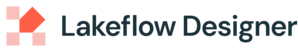
  <h2 class="lfd-title">What is Lakeflow Designer?</h2>
  <p class="lfd-subtitle">No-code data prep, ready for production. Native to Databricks.</p>
  <ul class="lfd-intro-list">
    <li>A <strong>visual, no-code, AI-native experience</strong> for data preparation and analytics, built directly into Databricks.</li>
    <li>Drag operators onto a <strong>canvas</strong> to ingest, clean, join, and transform data.</li>
    <li><strong>Preview inputs and outputs at every step</strong> to catch issues early.</li>
    <li>Workflows are backed by <strong>production-ready code</strong> and fully governed by <strong>Unity Catalog</strong>.</li>
    <li>Moves from <strong>prototype to production</strong> without a rebuild.</li>
  </ul>
  <span class="lfd-badge">Now in GA</span>
</div>

<img src="./Includes/images/common/lakeflow-designer-hero-img.png"
     alt="Lakeflow Designer canvas"
     class="lfd-screenshot-img" />

<div class="lfd-pillars">

  <div class="lfd-card one">
    <div class="lfd-card-title">Simple path to production</div>
    <div class="lfd-card-sub">Build once, run in production.</div>
    <ul class="lfd-card-list">
      <li>Run in production with <strong>Lakeflow Jobs</strong>.</li>
      <li>No rebuild, no rewrite, no handoff.</li>
      <li>Same artifact in dev and prod.</li>
    </ul>
  </div>

  <div class="lfd-card two">
    <div class="lfd-card-title">AI-native and reviewable</div>
    <div class="lfd-card-sub">Natural language you can inspect.</div>
    <ul class="lfd-card-list">
      <li>Describe transformations in plain English.</li>
      <li><strong>Genie Code</strong> uses your schema, lineage, and business context.</li>
      <li>Inspect, validate, and trust every step.</li>
    </ul>
  </div>

  <div class="lfd-card three">
    <div class="lfd-card-title">Self-service, fully governed</div>
    <div class="lfd-card-sub">Where your data already lives.</div>
    <ul class="lfd-card-list">
      <li>Prep data on the Databricks Data Intelligence Platform.</li>
      <li><strong>Unity Catalog</strong> governance, lineage, and permissions apply automatically.</li>
      <li>No separate licenses, consumption-based pricing.</li>
    </ul>
  </div>

</div>

<div class="lfd-audience">
  <div class="lfd-audience-header"><svg class="lfd-audience-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.8" stroke-linecap="round" stroke-linejoin="round" aria-hidden="true"><circle cx="9" cy="8" r="3.2"></circle><circle cx="17" cy="9" r="2.4"></circle><path d="M2.5 19c0-3 3-5 6.5-5s6.5 2 6.5 5"></path><path d="M15 14.5c2.8 0 6 1.6 6 4.5"></path></svg><h3 class="lfd-audience-title">Who it is for</h3></div>
  <div class="lfd-personas">
    <div class="lfd-persona-pill">Business Users</div>
    <div class="lfd-persona-pill">Analysts</div>
    <div class="lfd-persona-pill">Analytics Engineers</div>
    <div class="lfd-persona-pill">Data Engineers</div>
  </div>
</div>

<div class="lfd-learn-more">
  <div class="lfd-learn-more-title">Learn more</div>
  <ul class="lfd-learn-more-list">
    <li><a href="https://www.databricks.com/product/data-engineering/lakeflow-designer" target="_blank">Product page: Lakeflow Designer</a></li>
    <li><a href="https://www.databricks.com/blog/lakeflow-new-era-agentic-data-engineering" target="_blank">Lakeflow: A new era of agentic data engineering</a></li>
    <li>
      Docs:
      <a href="https://docs.databricks.com/aws/en/designer/" target="_blank">AWS</a> &nbsp;|&nbsp;
      <a href="https://learn.microsoft.com/en-us/azure/databricks/designer/" target="_blank">Azure</a> &nbsp;|&nbsp;
      <a href="https://docs.databricks.com/gcp/en/designer/" target="_blank">GCP</a>
    </li>
  </ul>
</div>

</div>


## B. Open and Explore Lakeflow Designer

### B1. Create a Visual Data Prep File in Lakeflow Designer

> Keeping this notebook on one tab and Lakeflow Designer on another makes the rest of the demo easier to follow.

1. In the **workspace sidebar**, select the **Folder** icon.

2. In your main folder, select **More Options** > **Create** > **Visual data prep**.
   - **NOTE:** You can also use the main navigation bar and select **+ New** > **Visual data prep**.

3. A new file opens with an auto-generated name like `Visual data prep YYYY-MM-DD HH:MM:SS`.

4. Click the name at the top of the page and rename the file to `meeting_visual_data_prep - YOUR INITIALS`.

5. **Lakeflow Designer** should now be open and ready to use.

6. (OPTIONAL) In your folder, locate the `meeting_visual_data_prep - YOUR INITIALS` visual data prep. 
   - Right-click the file and select **Open in new browser tab** so you can follow along with these instructions.

### B2. Explore the Lakeflow Designer UI

1. Take a quick tour of the screen before you do anything. Lakeflow Designer has a few main areas:

| Area | Where it is | What it does |
|---|---|---|
| **Canvas** | Center of the screen | The visual graph where your workflow lives. Operators connect together here to form the data flow. |
| **Getting started panel** | Center, shown when the canvas is empty | Provides shortcuts for adding your first source. You can also use **Genie Code** to start creating your visual workflow. We will walk through these options step by step in this workshop. |
| **Operators panel** | Left sidebar, **Operators** tab | The building blocks you drag onto the canvas. Grouped into **Source and output**, **AI transformations**, and **Transformations**. |
| **Parameters panel** | Left sidebar, **Parameters** tab | Reusable values you can reference across the workflow. Empty for now. |
| **Compute selector** | Top right, shows **Serverless** | The compute that runs your previews and the final workflow run. |
| **Schedule** and **Share** | Top right | Schedule the workflow to run on a cadence, or share it with teammates. |
| **Preview panel** | Bottom of the canvas | Shows sample rows and schema for the operator you currently have selected. Updates as you build. |

2. Click the **Operators** tab on the left and scroll through the list.
    - **Built-in operators in Lakeflow Designer**: [AWS](https://docs.databricks.com/aws/en/designer/built-in-operators) | 
    [Azure](https://learn.microsoft.com/en-us/azure/databricks/designer/built-in-operators) | 
    [GCP](https://docs.databricks.com/gcp/en/designer/built-in-operators)

3. Click the **Parameters** tab. It is empty, which is expected.

4. Look at the **Getting started** panel in the center. Note the four ways to add data:
   - **Select a source** picks an existing Unity Catalog table.
   - **Upload a file** uploads a local file like a CSV. You will use this for the participant lookup later.
   - **Load a sample** loads a Databricks-provided sample dataset.
   - **Try an assistant prompt** lets the AI assistant generate a starting transformation from a natural language description.

5. Confirm the compute selector in the top right shows **Serverless**. We will use serverless compute for this workflow.

## C. Add Your Source Bronze Tables

In this section, you will add the three existing bronze tables (**feedback_bronze**, **participants_bronze**, **sessions_bronze**) to the canvas. We will use a different method for each table so you can see the options available in Lakeflow Designer.

<!--
  =============================================================================
  HOW TO GRAY OUT NODES
  =============================================================================
  Add class="dim" (alongside any existing classes) to any element you want to
  fade into the background.
  =============================================================================
-->
<div class="pipe-wrap">

<style>
.pipe-wrap {
    max-width: 920px;
    margin: 0 auto;
    font-family: sans-serif;
    color: #0b2026;
    padding: 8px;
    box-sizing: border-box;
}

/* Add class="dim" to any element to fade it into the background */
.dim {
    opacity: 0.30;
    filter: grayscale(100%);
}

.pipe-header {
    background: #1B5162;
    color: white;
    border-radius: 10px;
    padding: 22px 26px;
    text-align: center;
    margin-bottom: 22px;
    box-shadow: 0 2px 8px rgba(27,49,57,0.10);
}

.pipe-title {
    font-size: 20pt;
    font-weight: 700;
    color: white;
    margin: 0 0 10px 0;
}

.pipe-subtitle {
    font-size: 13pt;
    color: white;
    opacity: 0.94;
    line-height: 1.5;
    margin: 0;
    display: inline-block;
    text-align: left;
    padding-left: 24px;
}

.pipe-subtitle li { margin-bottom: 4px; }
.pipe-subtitle li:last-child { margin-bottom: 0; }
.pipe-subtitle strong { color: #FFAB00; font-weight: 700; }

.pipe-grid {
    display: grid;
    grid-template-columns: repeat(4, 1fr);
    column-gap: 14px;
    row-gap: 8px;
    align-items: stretch;
    justify-items: stretch;
}

.pipe-arrow-cell {
    display: flex;
    justify-content: center;
    align-items: center;
}

.pipe-node {
    width: 100%;
    height: 100%;
    background: #F9F7F4;
    border-radius: 8px;
    box-shadow: 0 2px 8px rgba(27,49,57,0.06);
    padding: 14px 10px 12px 10px;
    text-align: center;
    position: relative;
    box-sizing: border-box;
    display: flex;
    flex-direction: column;
    justify-content: flex-start;
}

.pipe-node::before {
    content: "";
    position: absolute;
    top: 0;
    left: 0;
    width: 100%;
    height: 6px;
    border-top-left-radius: 8px;
    border-top-right-radius: 8px;
}

.pipe-node.source::before      { background: #00A972; }
.pipe-node.bronze::before      { background: #CD7F32; }
.pipe-node.silver::before      { background: #90A5B1; }
.pipe-node.gold::before        { background: #FFAB00; }

/* Bonus card: dashed border instead of solid shadow */
.pipe-node.bonus {
    border: 2px dashed #B57F00;
    background: rgba(255, 171, 0, 0.06);
    box-shadow: none;
}

.bonus-badge {
    position: absolute;
    top: -10px;
    right: 8px;
    background: #B57F00;
    color: white;
    font-size: 8pt;
    font-weight: 700;
    letter-spacing: 1px;
    padding: 3px 8px;
    border-radius: 4px;
    text-transform: uppercase;
    z-index: 2;
}

.pipe-icon {
    width: 30px;
    height: 30px;
    margin: 4px auto 6px auto;
    display: block;
}

.pipe-node.source .pipe-icon      { color: #00A972; }
.pipe-node.bronze .pipe-icon      { color: #CD7F32; }
.pipe-node.silver .pipe-icon      { color: #5A6F77; }
.pipe-node.gold .pipe-icon        { color: #B57F00; }

.pipe-node-label {
    font-size: 9pt;
    font-weight: 700;
    letter-spacing: 1.5px;
    text-transform: uppercase;
    margin: 0 0 4px 0;
}

.pipe-node.source .pipe-node-label      { color: #00A972; }
.pipe-node.bronze .pipe-node-label      { color: #CD7F32; }
.pipe-node.silver .pipe-node-label      { color: #5A6F77; }
.pipe-node.gold .pipe-node-label        { color: #B57F00; }

.pipe-node-name {
    font-size: 11pt;
    font-weight: 700;
    color: #0b2026;
    word-break: break-word;
    line-height: 1.3;
    margin: 0 0 6px 0;
}

.pipe-node-desc {
    font-size: 12pt;
    font-weight: 400;
    color: #5E7077;
    line-height: 1.4;
    margin: 0;
}

.pipe-arrow {
    width: 22px;
    height: 28px;
    color: #5E7077;
}

.volume-wrapper {
    border: 2px dashed #1B5162;
    border-radius: 10px;
    padding: 10px 8px 10px 8px;
    background: rgba(27,81,98,0.04);
    box-sizing: border-box;
    height: 100%;
    display: flex;
    flex-direction: column;
}

.volume-label {
    font-size: 8.5pt;
    font-weight: 700;
    letter-spacing: 1.5px;
    text-transform: uppercase;
    color: #1B5162;
    text-align: center;
    margin: 0 0 8px 0;
}

.upstream-wrapper {
    border: 2px dashed #5E7077;
    border-radius: 10px;
    padding: 10px 14px;
    background: rgba(94,112,119,0.06);
    box-sizing: border-box;
    height: 100%;
    display: flex;
    flex-direction: column;
}

.upstream-label {
    font-size: 10pt;
    font-weight: 700;
    letter-spacing: 1.5px;
    text-transform: uppercase;
    color: #5E7077;
    text-align: center;
    margin: 0 0 8px 0;
}

.upstream-body {
    display: flex;
    align-items: center;
    gap: 14px;
    flex: 1;
    padding: 4px 8px;
}

.upstream-icon {
    width: 36px;
    height: 36px;
    color: #5E7077;
    flex-shrink: 0;
}

.upstream-title {
    font-size: 14pt;
    font-weight: 700;
    color: #0b2026;
    margin-bottom: 4px;
    line-height: 1.3;
}

.upstream-desc {
    font-size: 12pt;
    color: #5E7077;
    line-height: 1.4;
}

.silver-to-gold {
    display: flex;
    flex-direction: column;
    align-items: center;
    margin: 14px 0 18px 0;
}

.silver-to-gold svg {
    width: 30px;
    height: 38px;
    color: #5E7077;
}

.silver-to-gold-caption {
    font-size: 13pt;
    font-weight: 700;
    color: #1B5162;
    margin-top: 4px;
}

.gold-grid {
    display: grid;
    grid-template-columns: repeat(3, 1fr);
    column-gap: 14px;
    margin-top: 0;
}
</style>

<div class="pipe-header">
  <h3 class="pipe-title">The Visual Workflow You Will Build</h3>
  <ul class="pipe-subtitle">
    <li>Import a local CSV file into a volume.</li>
    <li>Bronze gets cleaned into <strong>silver</strong>.</li>
    <li>Two gold tables are derived from silver. A bonus AI-powered table is offered as homework.</li>
  </ul>
</div>

<div class="pipe-grid">

  <!-- Row 1: Source (CSV) + Upstream ETL banner -->
  <div style="grid-column: 1; grid-row: 1;">
    <div class="volume-wrapper">
      <div class="volume-label">Manual File Upload to a Volume</div>
      <div class="pipe-node source">
        <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><path d="M5 2h11l4 4v15a1 1 0 0 1-1 1H5a1 1 0 0 1-1-1V3a1 1 0 0 1 1-1z"/><path d="M16 2v4h4"/><text x="12" y="19" text-anchor="middle" font-family="sans-serif" font-size="10" font-weight="700" stroke="none" fill="currentColor">CSV</text></svg>
        <div class="pipe-node-label">CSV File</div>
        <p class="pipe-node-name">how_participant_lookup_week_1.csv</p>
        <p class="pipe-node-desc">Uploaded participant directory</p>
      </div>
    </div>
  </div>

  <div style="grid-column: 2 / span 3; grid-row: 1;">
    <div class="upstream-wrapper">
      <div class="upstream-label">Upstream workflow &middot; Runs on a Schedule</div>
      <div class="upstream-body">
        <svg class="upstream-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.6" stroke-linecap="round" stroke-linejoin="round" aria-hidden="true">
          <path d="M21 12a9 9 0 1 1-3.51-7.12"/>
          <polyline points="21 4 21 9 16 9"/>
        </svg>
        <div>
          <div class="upstream-title">Source workflow managed by another team</div>
          <div class="upstream-desc">Another team ingests the meeting source data as bronze tables on a schedule, refreshing the tables with new sessions, attendees, and feedback. You will keep silver and gold updated.</div>
        </div>
      </div>
    </div>
  </div>

  <!-- Row 2: arrows from CSV and Upstream ETL down to bronze -->
  <div class="pipe-arrow-cell" style="grid-column: 1; grid-row: 2;">
    <svg class="pipe-arrow" viewBox="0 0 20 30" fill="none" aria-hidden="true"><line x1="10" y1="0" x2="10" y2="22" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"/><polygon points="3,21 17,21 10,30" fill="currentColor"/></svg>
  </div>
  <div class="pipe-arrow-cell" style="grid-column: 2; grid-row: 2;">
    <svg class="pipe-arrow" viewBox="0 0 20 30" fill="none" aria-hidden="true"><line x1="10" y1="0" x2="10" y2="22" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"/><polygon points="3,21 17,21 10,30" fill="currentColor"/></svg>
  </div>
  <div class="pipe-arrow-cell" style="grid-column: 3; grid-row: 2;">
    <svg class="pipe-arrow" viewBox="0 0 20 30" fill="none" aria-hidden="true"><line x1="10" y1="0" x2="10" y2="22" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"/><polygon points="3,21 17,21 10,30" fill="currentColor"/></svg>
  </div>
  <div class="pipe-arrow-cell" style="grid-column: 4; grid-row: 2;">
    <svg class="pipe-arrow" viewBox="0 0 20 30" fill="none" aria-hidden="true"><line x1="10" y1="0" x2="10" y2="22" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"/><polygon points="3,21 17,21 10,30" fill="currentColor"/></svg>
  </div>

  <!-- Row 3: Bronze tables -->
  <div style="grid-column: 1; grid-row: 3;">
    <div class="pipe-node bronze">
      <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
      <div class="pipe-node-label">Bronze</div>
      <p class="pipe-node-name">participant_lookup_bronze</p>
      <p class="pipe-node-desc">Lookup ingested from the CSV</p>
    </div>
  </div>
  <div style="grid-column: 2; grid-row: 3;">
    <div class="pipe-node bronze">
      <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
      <div class="pipe-node-label">Bronze</div>
      <p class="pipe-node-name">sessions_bronze</p>
      <p class="pipe-node-desc">Raw session metadata, one row per session</p>
    </div>
  </div>
  <div style="grid-column: 3; grid-row: 3;">
    <div class="pipe-node bronze">
      <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
      <div class="pipe-node-label">Bronze</div>
      <p class="pipe-node-name">participants_bronze</p>
      <p class="pipe-node-desc">Attendance log, one row per attendee per session</p>
    </div>
  </div>
  <div style="grid-column: 4; grid-row: 3;">
    <div class="pipe-node bronze">
      <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
      <div class="pipe-node-label">Bronze</div>
      <p class="pipe-node-name">feedback_bronze</p>
      <p class="pipe-node-desc">Survey responses stored as a JSON array per session</p>
    </div>
  </div>

  <!-- Row 4: Bronze -> Silver arrows -->
  <div class="pipe-arrow-cell" style="grid-column: 1; grid-row: 4;"><svg class="pipe-arrow" viewBox="0 0 20 30" fill="none" aria-hidden="true"><line x1="10" y1="0" x2="10" y2="22" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"/><polygon points="3,21 17,21 10,30" fill="currentColor"/></svg></div>
  <div class="pipe-arrow-cell" style="grid-column: 2; grid-row: 4;"><svg class="pipe-arrow" viewBox="0 0 20 30" fill="none" aria-hidden="true"><line x1="10" y1="0" x2="10" y2="22" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"/><polygon points="3,21 17,21 10,30" fill="currentColor"/></svg></div>
  <div class="pipe-arrow-cell" style="grid-column: 3; grid-row: 4;"><svg class="pipe-arrow" viewBox="0 0 20 30" fill="none" aria-hidden="true"><line x1="10" y1="0" x2="10" y2="22" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"/><polygon points="3,21 17,21 10,30" fill="currentColor"/></svg></div>
  <div class="pipe-arrow-cell" style="grid-column: 4; grid-row: 4;"><svg class="pipe-arrow" viewBox="0 0 20 30" fill="none" aria-hidden="true"><line x1="10" y1="0" x2="10" y2="22" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"/><polygon points="3,21 17,21 10,30" fill="currentColor"/></svg></div>

  <!-- Row 5: Silver tables -->
  <div style="grid-column: 1; grid-row: 5;">
    <div class="pipe-node silver dim">
      <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
      <div class="pipe-node-label">Silver</div>
      <p class="pipe-node-name">participant_lookup_silver</p>
      <p class="pipe-node-desc">Email and region split into parts</p>
    </div>
  </div>
  <div style="grid-column: 2; grid-row: 5;">
    <div class="pipe-node silver dim">
      <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
      <div class="pipe-node-label">Silver</div>
      <p class="pipe-node-name">sessions_silver</p>
      <p class="pipe-node-desc">Date typed, how_name renamed to session_name</p>
    </div>
  </div>
  <div style="grid-column: 3; grid-row: 5;">
    <div class="pipe-node silver dim">
      <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
      <div class="pipe-node-label">Silver</div>
      <p class="pipe-node-name">participants_silver</p>
      <p class="pipe-node-desc">Timestamps typed, duration_in_minutes added</p>
    </div>
  </div>
  <div style="grid-column: 4; grid-row: 5;">
    <div class="pipe-node silver dim">
      <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
      <div class="pipe-node-label">Silver</div>
      <p class="pipe-node-name">feedback_silver</p>
      <p class="pipe-node-desc">JSON exploded, one row per response</p>
    </div>
  </div>

</div>

<!-- Single centered arrow between silver and gold -->
<div class="silver-to-gold">
  <svg width="30" height="38" viewBox="0 0 30 38" fill="none" aria-hidden="true"><line x1="15" y1="2" x2="15" y2="26" stroke="currentColor" stroke-width="3" stroke-linecap="round"/><polygon points="4,26 26,26 15,38" fill="currentColor"/></svg>
  <div class="silver-to-gold-caption">Join and aggregate</div>
</div>

<!-- Gold row: 2 main gold tables + 1 bonus -->
<div class="gold-grid">
  <div class="pipe-node gold dim">
    <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
    <div class="pipe-node-label">Gold</div>
    <p class="pipe-node-name">gold_session_summary</p>
    <p class="pipe-node-desc">Session metadata with attendance metrics</p>
  </div>
  <div class="pipe-node gold dim">
    <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
    <div class="pipe-node-label">Gold</div>
    <p class="pipe-node-name">gold_feedback_summary</p>
    <p class="pipe-node-desc">Session-level average ratings</p>
  </div>
  <div class="pipe-node gold bonus dim">
    <div class="bonus-badge">Bonus / Homework</div>
    <svg class="pipe-icon" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="1.5" stroke-linejoin="round" stroke-linecap="round" aria-hidden="true"><rect x="3" y="4" width="18" height="16" rx="1"/><line x1="3" y1="9" x2="21" y2="9"/><line x1="3" y1="14" x2="21" y2="14"/><line x1="9" y1="4" x2="9" y2="20"/><line x1="15" y1="4" x2="15" y2="20"/></svg>
    <div class="pipe-node-label">Gold</div>
    <p class="pipe-node-name">gold_feedback_sentiment</p>
    <p class="pipe-node-desc">Free-form responses tagged with ai_sentiment</p>
  </div>
</div>

</div>


### C1. Method 1 - Source Operator

1. From the **Operators** panel on the left, drag the **Source** operator onto the canvas.

2. Select **Browse existing** to search Unity Catalog.

3. Select the **learn_no_code_etl_designer_USERNAME.designer_meeting.feedback_bronze** table.

4. View the **Preview** pane at the bottom of the canvas to confirm the data loaded.

### C2. Method 2 - Drag the Table into the Canvas

1. In the left sidebar, select the **Catalog** icon ![Catalog Icon](./Includes/images/common/catalog-icon.png).

2. Locate the **learn_no_code_etl_designer_USERNAME.designer_meeting.participants_bronze** table.

3. Select the **>>** button to add the table to the canvas. 

4. View the **Preview** pane to confirm the data loaded.

### C3. Method 3 - Use Genie Code

1. Click anywhere on an empty area of the canvas to deselect any node.

2. In the **Genie Code** prompt bar, enter the following prompt: `Add the designer_meeting.sessions_bronze table`.

3. Select **Accept all**.

4. View the **Preview** pane to confirm the data loaded.

#### C3.1. Data Profiling in Lakeflow Designer

1. Navigate to the preview pane for the **designer_meeting.sessions_bronze**.

2. In the top right corner of the output pane, choose the **Sidebar** icon. 
    - The sidebar button to opens the selection details. 
    - You can select columns in your table explore the values.

3. Select the **planned_duration_minutes** column.

    ![Profile](./Includes/images/visual_etl_pipeline/data-profiling.png)

This will profile the data.
- By default uses a **sample** of the data.
- You can switch to use the **full dataset**.

#### Checkpoint - 3 Source Tables
![Source Tables](./Includes/images/visual_etl_pipeline/checkpoint-bronze-source-tables.png)

## D. Upload a Local File

When uploading you can:

- Upload raw file to a volume in Unity Catalog. Then you can read the file(s) as a table.
- Upload and create a table in Unity Catalog



<div style="
  border-left: 4px solid #1976d2;
  background: #e3f2fd;
  padding: 14px 18px;
  border-radius: 4px;
  margin: 16px 0;
">
  <strong style="display:block; color:#0d47a1; margin-bottom:6px; font-size: 1.1em;">
    Information
  </strong>
  <div style="color:#333;">

In this section, you will download a CSV file locally, then upload it into Lakeflow Designer as a new source table. This simulates the common pattern of bringing in an external lookup file alongside your existing Unity Catalog tables.
  </div>
</div>


### D1. Download the File Locally

1. Back in this notebook, select the **Folder** icon in your workspace sidebar.

2. Open the **participant_lookup** folder and download the `how_participant_lookup_week_1.csv` file locally.

### D2. Upload the File and Create a Table in Lakeflow Designer

1. In Lakeflow Designer, drag the **Source** operator onto the canvas below the **sessions_bronze** node.

2. Double-click the **Source** operator to open the operator panel.

3. Select **Create table from file**

4. Upload the file to the page.

5. Set the following:

    | Setting | Value |
    |---|---|
    | **Catalog** | `learn_no_code_etl_designer_USERNAME` |
    | **Schema** | `designer_meeting` |
    | **Table name** | `participant_information` |

5. Select **Create table**.

6. On the right panel, you should see the source configuration options.

    - At the top, select the auto-generated **source_#** node name.

    - Rename the node to `participant_lookup_bronze`.

    - Confirm the preview of the data looks correct.

## E. Auto Layout the Nodes

As you add nodes, you can either reposition them manually or let Lakeflow Designer arrange them for you.

1. In the main Lakeflow Designer toolbar, select the **Auto Layout** ![Layout](./Includes/images/common/auto-layout-icon.png) icon to organize the nodes in the canvas.

You now have all four bronze sources on the canvas. In the next demo (**03 - Build the Silver Layer**), you will clean and transform these tables into silver.


&copy; <span id="dbx-year"></span> Databricks, Inc. All rights reserved.
Apache, Apache Spark, Spark, the Spark Logo, Apache Iceberg, Iceberg, and the Apache Iceberg logo are trademarks of the <a href="https://www.apache.org/" target="_blank">Apache Software Foundation</a>.<br/><br/><a href="https://databricks.com/privacy-policy" target="_blank">Privacy Policy</a> | <a href="https://databricks.com/terms-of-use" target="_blank">Terms of Use</a> | <a href="https://help.databricks.com/" target="_blank">Support</a>
<script>
  document.getElementById("dbx-year").textContent = new Date().getFullYear();
</script>